# Test singularity tracing in sum-of-products KEO of $\mathrm{HCN}$ using Jacobi coordinates

The kinetic energy operator (KEO) for a triatomic molecule in Jacobi coordinates $(R,r,\theta)$ has a simple analytical form.
However, it contains terms that become singular at linear geometries ($\theta=0,\pi$), specifically in the pseudopotential $U$ and the rotational KEO components $G_{zz}$ and $G_{xz}$.

Here, we test the capability of `keosop` to accurately identify and represent these singular terms.
We compute $U$, $G_{zz}$, and $G_{xz}$ in sum-of-products form and compare them with their analytical expressions by evaluating and plotting them on a grid along the Jacobi angular coordinate $\theta$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from scipy import constants

from keosop.sing.gmat import Gmat
from keosop.sing.revad import dot, norm

sns.set_theme(style="ticks", context="paper", font_scale=1.5)
plt.rcParams["figure.dpi"] = 300
plt.rcParams.update({"text.usetex": True, "font.family": "serif", "font.size": 14})

# converts G-matrix to cm^-1 units
G_to_invcm = (
    constants.value("Planck constant")
    * constants.value("Avogadro constant")
    * 1e16
    / (4.0 * np.pi**2 * constants.value("speed of light in vacuum"))
    * 1e5
)

Define the internal-to-Cartesian and Cartesian-to-internal coordinate transformations for HCN in Jacobi coordinates.

In [2]:
masses = np.array([1.0078250, 15.99491463, 14.003074004251])  # masses of H, C, N


def internal_to_cartesian(q):
    R, r, theta = q

    mH, mC, mN = masses
    mCN = mC + mN

    C = np.array([0.0, 0.0, -mN / mCN * r], dtype=object)
    N = np.array([0.0, 0.0, mC / mCN * r], dtype=object)
    H = np.array([R * np.sin(theta), 0.0, R * np.cos(theta)], dtype=object)

    return np.array([H, C, N], dtype=object)


def cartesian_to_internal(xyz):
    H, C, N = xyz

    mH, mC, mN = masses
    mCN = mC + mN

    rvec = N - C
    r = norm(rvec)

    comCN = (mC * C + mN * N) / mCN

    Rvec = H - comCN
    R = norm(Rvec)

    theta = np.arccos(dot(rvec, Rvec) / (r * R))

    return np.array([R, r, theta], dtype=object)

Define one-dimensional grids for the internal coordinate representation and construct the G-matrix and pseudopotential in sum-of-products form

In [3]:
# define 1D gris, essentially only for theta coordinate
grids = [
    np.linspace(1.7, 1.7, 1),  # R
    np.linspace(1.2, 1.2, 1),  # r
    np.linspace(0.1 * np.pi / 180, 179.9 * np.pi / 180, 1000),  # theta
]

ncoo = len(grids)

gmat = Gmat(
    grids,
    masses,
    internal_to_cartesian,
    cartesian_to_internal,
    trace_singularities=True,
    singularity_coo=(2,),
    singularity_kinds=("sin",),
)

# compute G-matrix and pseudopotential
gvib_sop, grovib_sop, grot_sop = gmat.run(return_rot=True)
pseudo_sop = gmat.build_pseudopotential_fdf(fd_step=0.001)

print("Number of terms in Gvib_{i,j}\n i  j no.terms  sing. summary")
for i in range(ncoo):
    for j in range(i, ncoo):
        print(
            f"{i:2d} {j:2d} {gvib_sop[i, j].nterms:6d}    {gvib_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in Grovib_{i,j}\n i  j no.terms  sing. summary")
for i in range(3):
    for j in range(ncoo):
        print(
            f"{i:2d} {j:2d} {grovib_sop[i, j].nterms:6d}    {grovib_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in Grot_{i,j}\n i  j no.terms  sing. summary")
for i in range(3):
    for j in range(i, 3):
        print(
            f"{i:2d} {j:2d} {grot_sop[i, j].nterms:6d}    {grot_sop[i,j].singularity_summary()}"
        )

print("\nNumber of terms in pseudopotential\n no.terms  sing. summary")
print(f"{pseudo_sop.nterms:6d}    {pseudo_sop.singularity_summary()}")

Number of terms in Gvib_{i,j}
 i  j no.terms  sing. summary
 0  0      1    {(): 1}
 0  1      1    {(): 1}
 0  2      1    {(): 1}
 1  1      1    {(): 1}
 1  2      1    {(): 1}
 2  2      1    {(): 1}

Number of terms in Grovib_{i,j}
 i  j no.terms  sing. summary
 0  0      1    {(): 1}
 0  1      1    {(): 1}
 0  2      1    {(): 1}
 1  0      1    {(): 1}
 1  1      1    {(): 1}
 1  2      1    {(): 1}
 2  0      1    {(): 1}
 2  1      1    {(): 1}
 2  2      1    {(): 1}

Number of terms in Grot_{i,j}
 i  j no.terms  sing. summary
 0  0      1    {(): 1}
 0  1      1    {(): 1}
 0  2      1    {((2, 'sin', -2.0),): 1}
 1  1      1    {(): 1}
 1  2      1    {(): 1}
 2  2      1    {((2, 'sin', -2.0),): 1}

Number of terms in pseudopotential
 no.terms  sing. summary
     2    {((2, 'sin', -2.0),): 1, (): 1}


As can be seen from the output of the previous cell, the pseudopotential contains one term proportional to $\sin^{-2}(q_2)$ and one regular (non-singular) term.
Thus, it can be written as $U = U_0 + \frac{U_1}{\sin^2\theta}$.
Since the decomposition into $U_0$ and $U_1$ is not unique, we instead compare the following quantity with its analytical expression $\tilde{U} = \sin^2\theta\, U_0 + U_1$.

Similarly, we also compare $\tilde{G}_{zz}=\sin^2\theta G_{zz}$ and $\tilde{G}_{xz}=\sin^2\theta G_{xz}$ with the exact analytical expressions.

Below, $\tilde{U}$, $\tilde{G}_{zz}$, and $\tilde{G}_{xz}$ are evaluated on a grid along the angular coordinate $\theta$ and compared with the corresponding analytical result.

In [4]:
# evaluate one SOP term
def eval_sop_term(sop, iterm, inds, grids):

    theta = grids[-1][inds[-1]]

    # regular numerical SOP part
    value = 1.0
    for k in range(sop.ncoo):
        value *= sop.terms[iterm][k][inds[k]]

    # if term contains no analytical singular part -> multiply it by sin^2(theta)
    if not sop.singularities[iterm]:
        value *= np.sin(theta) ** 2

    # if term contains sin^2(q[2]) analytical singular part -> skip evaluation of singular prefactor
    for k, kind, power in sop.singularities[iterm]:
        q = grids[k][inds[k]]
        if kind == "sin" and k == 2:
            continue
        else:
            raise ValueError(f"Unknown singularity kind: {kind}, coo. {k}")

    return value


# evaluate a complete SumProd object at one direct-product grid point
def eval_sop(sop, inds, grids):
    return sum(eval_sop_term(sop, iterm, inds, grids) for iterm in range(sop.nterms))


grid = np.stack(np.meshgrid(*grids, indexing="ij"), axis=-1)
grid = grid.reshape(-1, len(grids))
npoints = grid.shape[0]

grot_zz_sop_eval = np.zeros((npoints,), dtype=np.float64)
grot_xz_sop_eval = np.zeros((npoints,), dtype=np.float64)
pseudo_sop_eval = np.zeros((npoints,), dtype=np.float64)

# map each multidimensional grid point to its 1D grid indices
grid_indices = np.indices([len(elem) for elem in grids]).reshape(len(grids), -1).T

for ipoint, inds in enumerate(grid_indices):
    grot_zz_sop_eval[ipoint] = eval_sop(grot_sop[2, 2], inds, grids) * G_to_invcm
    grot_xz_sop_eval[ipoint] = eval_sop(grot_sop[0, 2], inds, grids) * G_to_invcm
    pseudo_sop_eval[ipoint] = eval_sop(pseudo_sop, inds, grids) * G_to_invcm

Compute pseudopotential $\tilde{U}$ and the rotational KEO components $\tilde{G}_{zz}$ and $\tilde{G}_{zz}$ using analytical expressions (derived using Mathematica for example).

In [5]:
def pseudo_times_sin2theta_analytic(q):
    R, r, theta = q
    mH, mC, mN = masses

    A = (
        R**2 * mH * mN**2
        + mC**2 * (R**2 * mH + r**2 * mN)
        + mC * mN * ((r**2 + 2 * R**2) * mH + r**2 * mN)
    ) / (16 * r**2 * R**2 * mC * mH * mN * (mC + mN))

    U_regular_times_sin2theta = -2.0 * A * np.sin(theta) ** 2
    U_singular_times_sin2theta = -2.0 * A

    return (U_regular_times_sin2theta + U_singular_times_sin2theta) * G_to_invcm


def gzz_times_sin2theta_analytic(q):
    R, r, theta = q
    mH, mC, mN = masses

    Gzz_singular_times_sin2theta = (
        1 / (R**2 * mH)
        + 1 / (r**2 * (mC + mN))
        + 1 / (R**2 * (mC + mN))
        + np.cos(2 * theta) / (r**2 * (mC + mN))
        + np.cos(theta) ** 2 * mC / (r**2 * mN * (mC + mN))
        + np.cos(theta) ** 2 * mN / (r**2 * mC * (mC + mN))
    )

    return Gzz_singular_times_sin2theta * G_to_invcm


def gxz_times_sin2theta_analytic(q):
    R, r, theta = q
    mH, mC, mN = masses

    Gxz_singular_times_sin2theta = np.cos(theta) * np.sin(theta) * (1 / (r**2 * mC) + 1 / (r**2 * mN))

    return Gxz_singular_times_sin2theta * G_to_invcm


pseudo_analytic_eval = []
gzz_analytic_eval = []
gxz_analytic_eval = []

for point in grid:
    pseudo_analytic_eval.append(pseudo_times_sin2theta_analytic(point))
    gzz_analytic_eval.append(gzz_times_sin2theta_analytic(point))
    gxz_analytic_eval.append(gxz_times_sin2theta_analytic(point))

pseudo_analytic_eval = np.array(pseudo_analytic_eval)
gzz_analytic_eval = np.array(gzz_analytic_eval)
gxz_analytic_eval = np.array(gxz_analytic_eval)

Plot sum-of-products and analytical results

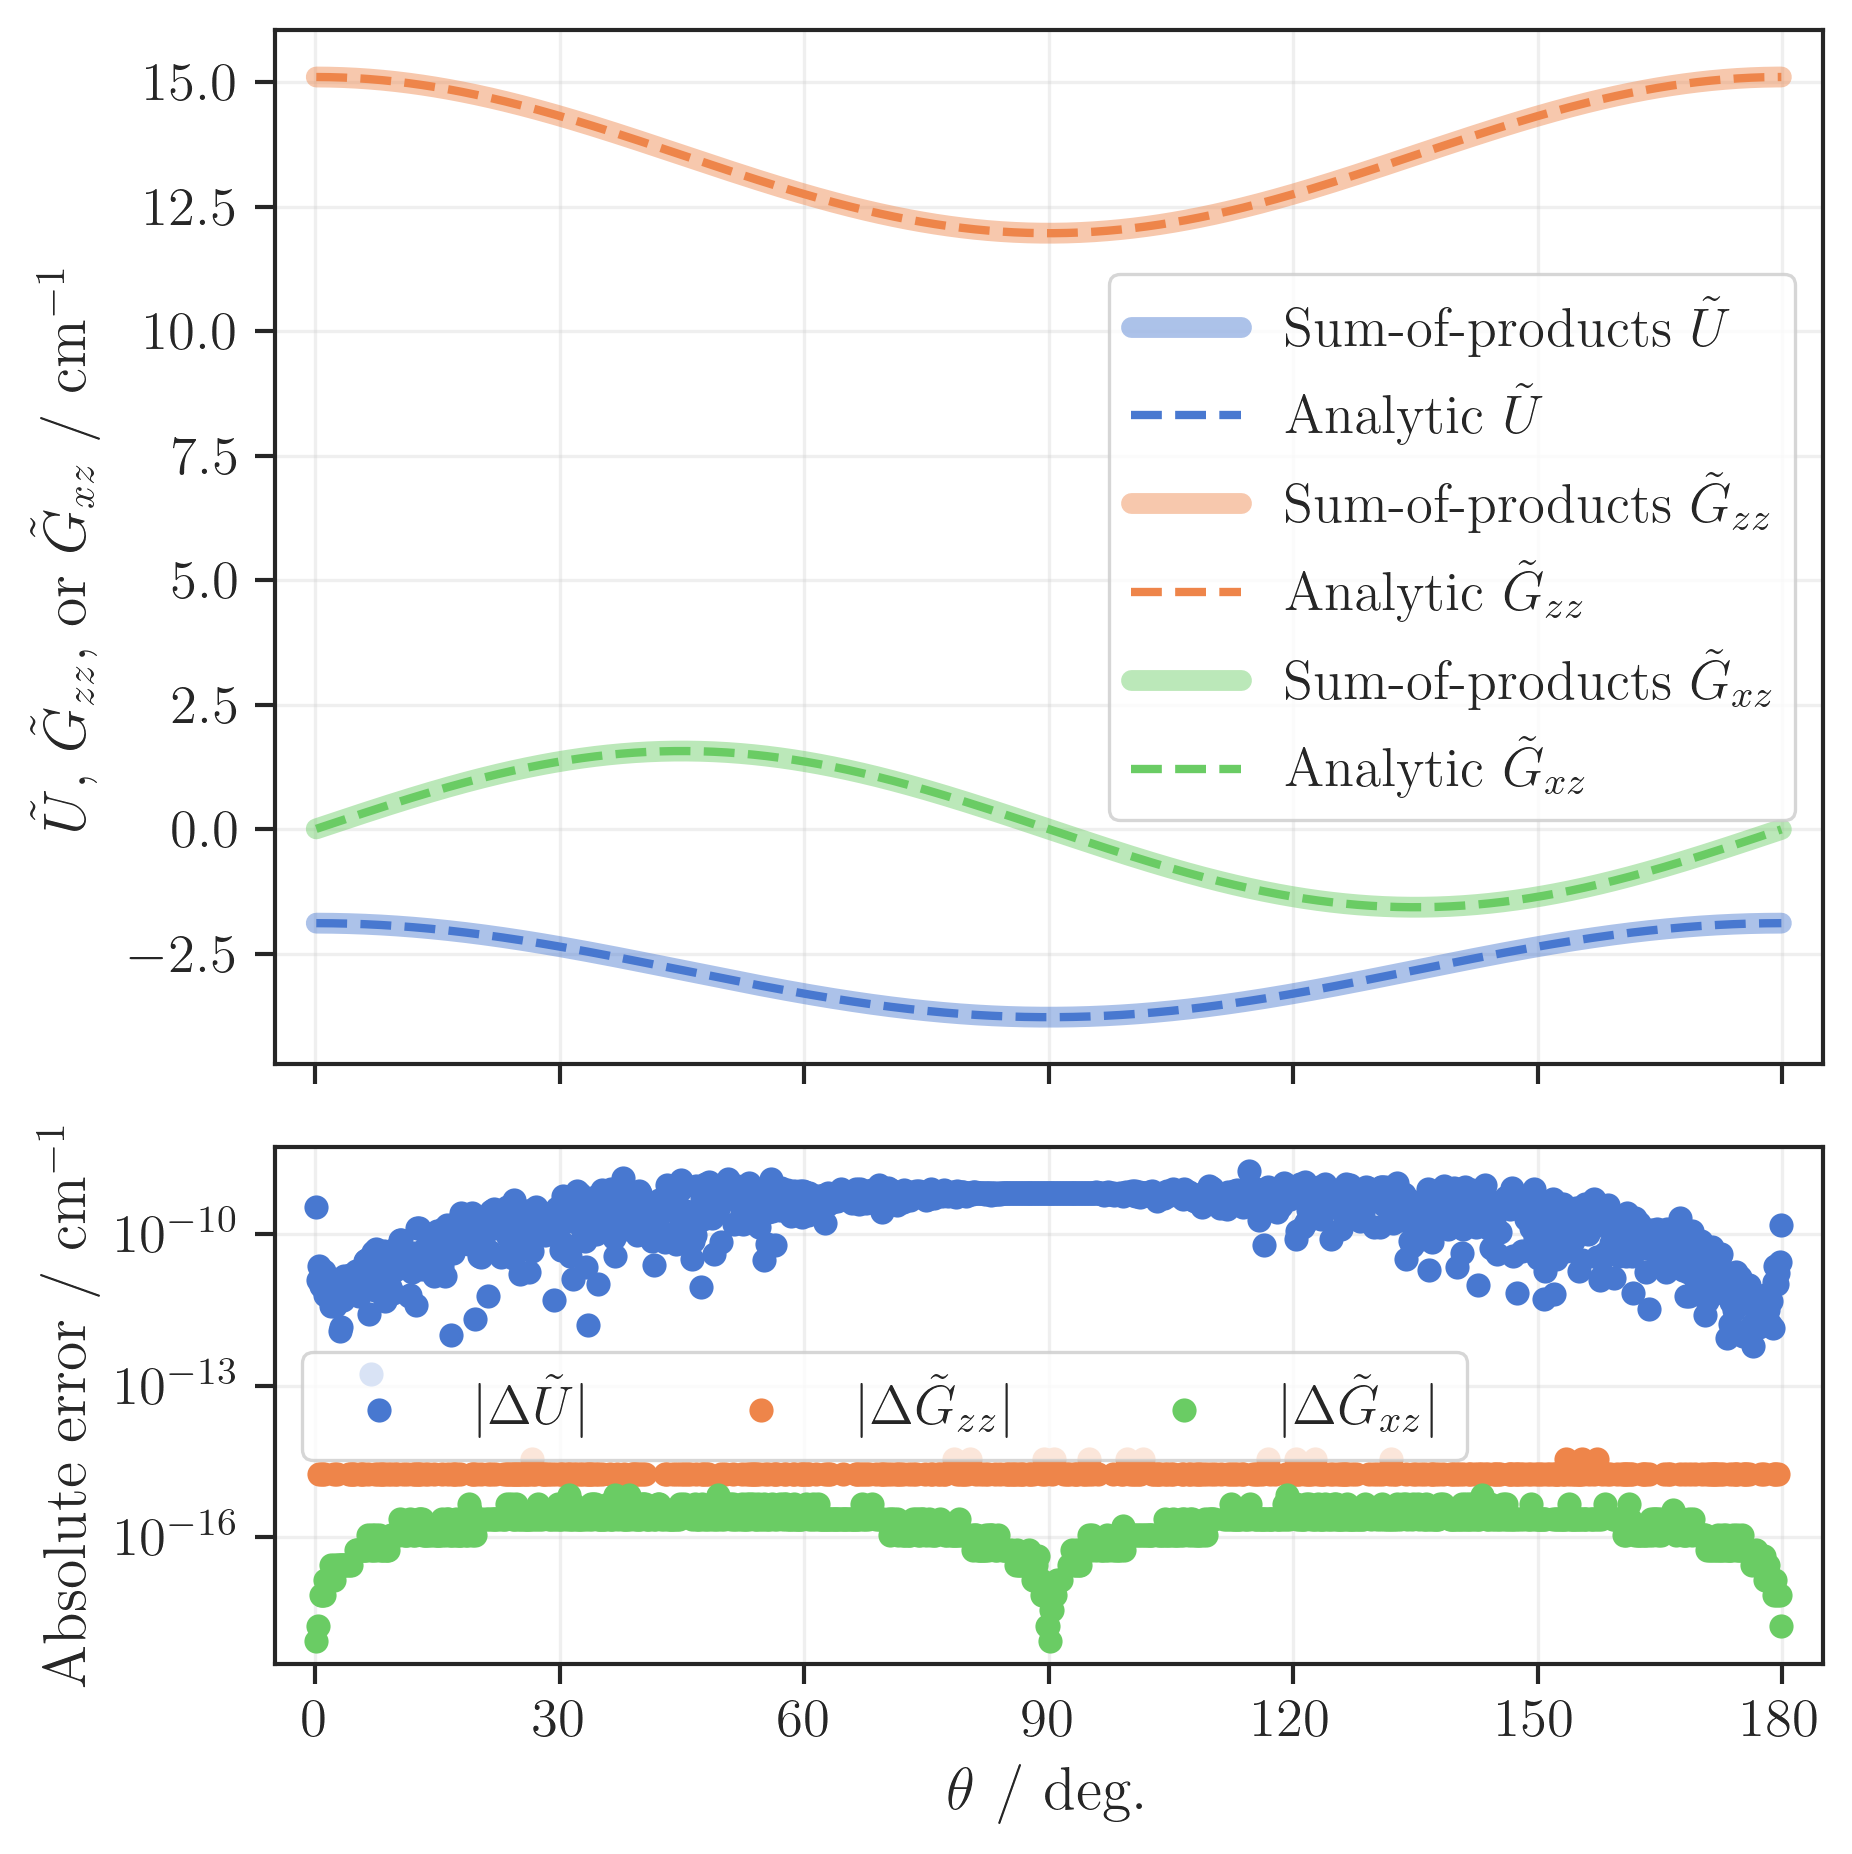

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

theta = grid[:, -1] * 180 / np.pi

colors = sns.color_palette("muted", n_colors=3)

scale = 0.8
fig, (ax1, ax2) = plt.subplots(
    2,
    1,
    figsize=(8 * scale, 8 * scale),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

curves = [
    (pseudo_sop_eval, pseudo_analytic_eval, r"$\tilde{U}$", colors[0]),
    (grot_zz_sop_eval, gzz_analytic_eval, r"$\tilde{G}_{zz}$", colors[1]),
    (grot_xz_sop_eval, gxz_analytic_eval, r"$\tilde{G}_{xz}$", colors[2]),
]

for sop, analytic, label, color in curves:
    ax1.plot(
        theta,
        sop,
        color=color,
        linewidth=5,
        alpha=0.45,
        label=rf"Sum-of-products {label}",
    )

    ax1.plot(
        theta,
        analytic,
        color=color,
        linewidth=2,
        linestyle="--",
        label=rf"Analytic {label}",
    )

ax1.set_ylabel(
    r"$\tilde{U}$, $\tilde{G}_{zz}$, or " r"$\tilde{G}_{xz}$ / $\mathrm{cm^{-1}}$"
)
ax1.set_xlim(-5, 185)
ax1.legend(ncol=1)
ax1.grid(True, alpha=0.3)


errors = [
    (np.abs(pseudo_sop_eval - pseudo_analytic_eval), r"$|\Delta\tilde{U}|$", colors[0]),
    (
        np.abs(grot_zz_sop_eval - gzz_analytic_eval),
        r"$|\Delta\tilde{G}_{zz}|$",
        colors[1],
    ),
    (
        np.abs(grot_xz_sop_eval - gxz_analytic_eval),
        r"$|\Delta\tilde{G}_{xz}|$",
        colors[2],
    ),
]

for error, label, color in errors:
    ax2.scatter(theta, error, color=color, label=label, s=25)

ax2.set_yscale("log")
ax2.set_xlim(-5, 185)
ax2.set_xticks(np.arange(0, 181, 30))
ax2.set_xlabel(r"$\theta$ / deg.")
ax2.set_ylabel(r"Absolute error / $\mathrm{cm^{-1}}$")
ax2.legend(ncol=3)
ax2.grid(True, alpha=0.3)

fig.align_ylabels()
fig.tight_layout()

fig.savefig("hcn_jacobi_sing.pdf", bbox_inches="tight", dpi=300)
plt.show()